# Telco Customer Churn Prediction

## 1. Introduction

Customer churn occurs when a customer stops using a company's services. Predicting churn can help telecommunications companies identify customers who may leave and develop appropriate customer-retention strategies.

### Objective

The objective of this project is to build and evaluate machine learning classification models that predict whether a telecommunications customer will churn.

### Models Used

* Logistic Regression
* Decision Tree
* Random Forest
* XGBoost

### Evaluation Metrics

The models will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

The project will also investigate the features associated with customer churn and compare the predictive performance of the four models.


In [1]:
# Import libraries for data handling
import numpy as np
import pandas as pd

# Import libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting the dataset and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# Import permutation importance
from sklearn.inspection import permutation_importance

# Set random seed for reproducibility
RANDOM_STATE = 42

# Set visualisation style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five rows
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names, data types, and non-null counts
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# Display descriptive statistics
print("\nDataset summary:")
display(df.describe(include="all"))

Dataset shape: (7043, 21)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Paper

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Dataset summary:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

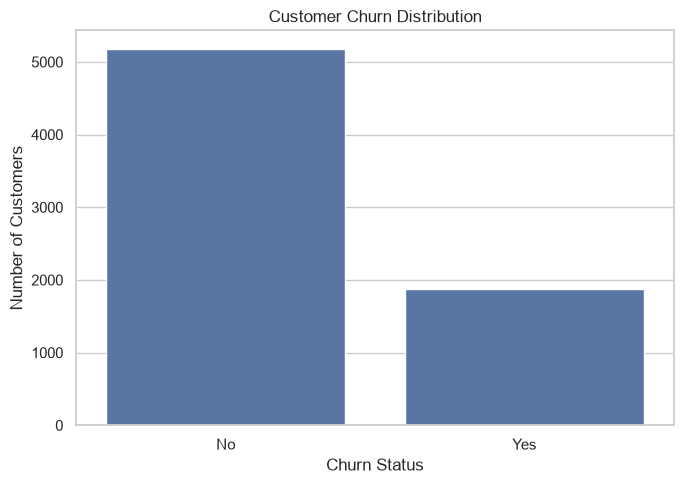

In [4]:
# Count customers in each churn category
print("Churn counts:")
display(df["Churn"].value_counts())

# Calculate percentages
print("\nChurn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

# Visualise the distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [5]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Remove the customer identifier
df_clean.drop(columns=["customerID"], inplace=True)

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Inspect the updated dataset
print("Dataset shape after removing customerID:", df_clean.shape)

print("\nUpdated data types:")
display(df_clean.dtypes)

print("\nMissing values after conversion:")
display(df_clean.isnull().sum())

Dataset shape after removing customerID: (7043, 20)

Updated data types:


gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


Missing values after conversion:


gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [6]:
# Inspect rows with missing TotalCharges
missing_charges = df_clean[df_clean["TotalCharges"].isnull()]

print("Number of rows with missing TotalCharges:", len(missing_charges))

print("\nTenure of customers with missing TotalCharges:")
display(missing_charges["tenure"].value_counts())

# Check exact duplicate rows in the original dataset
print("\nExact duplicate rows in the original dataset:")
print(df.duplicated().sum())

# Check duplicate rows after removing customerID
print("\nDuplicate rows after removing customerID:")
print(df_clean.duplicated().sum())

Number of rows with missing TotalCharges: 11

Tenure of customers with missing TotalCharges:


tenure
0    11
Name: count, dtype: int64


Exact duplicate rows in the original dataset:
0

Duplicate rows after removing customerID:
22


In [7]:
# Replace missing TotalCharges values with zero
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Encode the target variable
df_clean["Churn"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Verify the cleaned data
print("Dataset shape:", df_clean.shape)

print("\nTotal missing values remaining:")
print(df_clean.isnull().sum().sum())

print("\nChurn distribution:")
display(df_clean["Churn"].value_counts())

display(df_clean.head())

Dataset shape: (7043, 20)

Total missing values remaining:
0

Churn distribution:


Churn
0    5174
1    1869
Name: count, dtype: int64

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Churn rate by contract type:


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

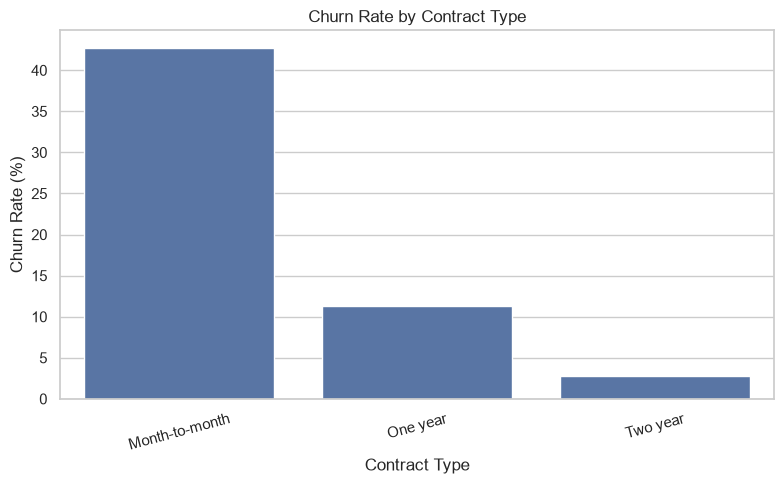

In [8]:
# Calculate churn rate for each contract type
contract_churn = (
    df_clean.groupby("Contract")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Churn rate by contract type:")
display(contract_churn.round(2))

# Visualise churn rate by contract type
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

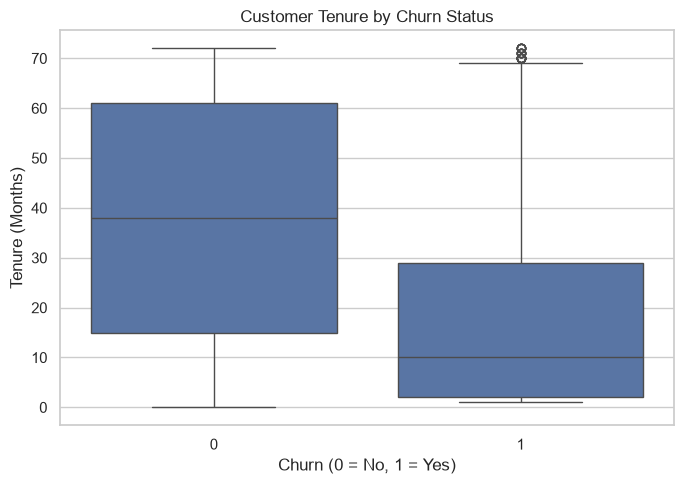

Average tenure by churn status:


Churn
0    37.57
1    17.98
Name: tenure, dtype: float64

In [9]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

print("Average tenure by churn status:")
display(df_clean.groupby("Churn")["tenure"].mean().round(2))

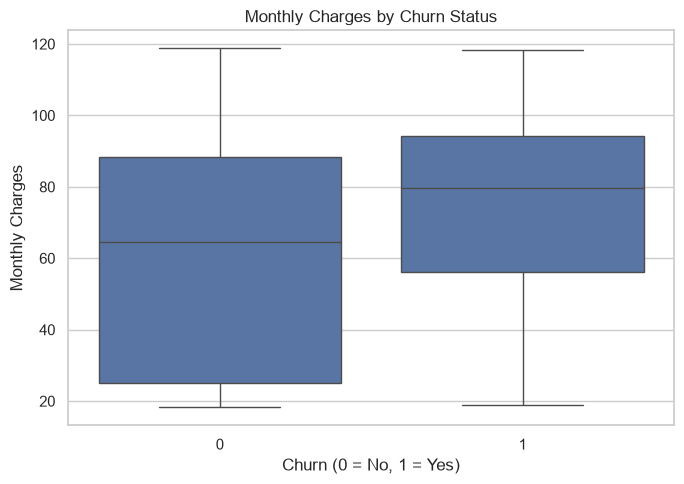

Average monthly charges by churn status:


Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64

In [10]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

print("Average monthly charges by churn status:")
display(df_clean.groupby("Churn")["MonthlyCharges"].mean().round(2))

In [11]:
# Separate input features and target
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (7043, 19)
Target shape: (7043,)


In [12]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining churn proportions:")
display(y_train.value_counts(normalize=True).round(4))

print("\nTesting churn proportions:")
display(y_test.value_counts(normalize=True).round(4))

Training set: (5634, 19)
Testing set: (1409, 19)

Training churn proportions:


Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


Testing churn proportions:


Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

In [13]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\NIYA ELSA LAIJI\AppData\Local\Temp\ipykernel_37064\2795189477.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [14]:
# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [15]:
# Calculate the class-weight ratio for XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))

# Define the four models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("\nFour models defined successfully.")

XGBoost scale_pos_weight: 2.769

Four models defined successfully.


In [19]:
# Create a pipeline for each model
model_pipelines = {}

for model_name, model in models.items():

    model_pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

# Train each model
for model_name, pipeline in model_pipelines.items():

    pipeline.fit(X_train, y_train)

    print(f"{model_name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
XGBoost trained successfully.


In [20]:
# Store evaluation results
results = []

# Store predictions and probabilities
predictions = {}
probabilities = {}

for model_name, pipeline in model_pipelines.items():

    # Predict class labels
    y_pred = pipeline.predict(X_test)

    # Predict probability of churn
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Save predictions for later plots
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Create the final comparison table
results_df = pd.DataFrame(results)

print("Final Model Comparison")
display(results_df.round(4))

Final Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
1,Decision Tree,0.7395,0.5060,0.7861,0.6157,0.8295
2,Random Forest,0.7700,0.5592,0.6310,0.5930,0.8213
3,XGBoost,0.7466,0.5147,0.7941,0.6246,0.8437


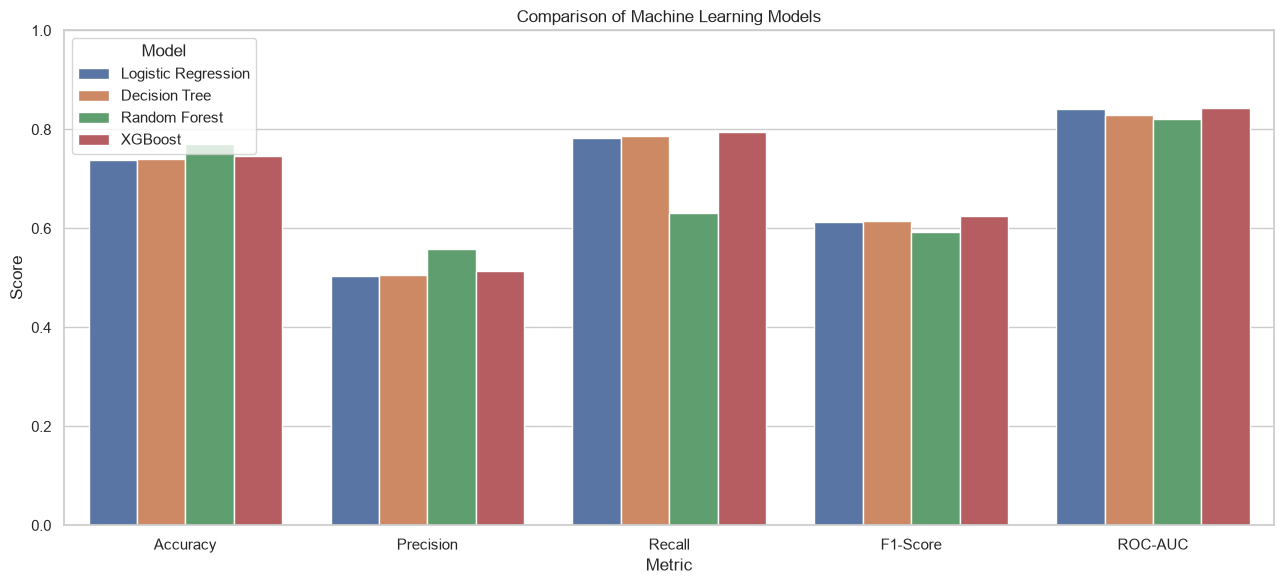

In [22]:
# Plot the evaluation metrics
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

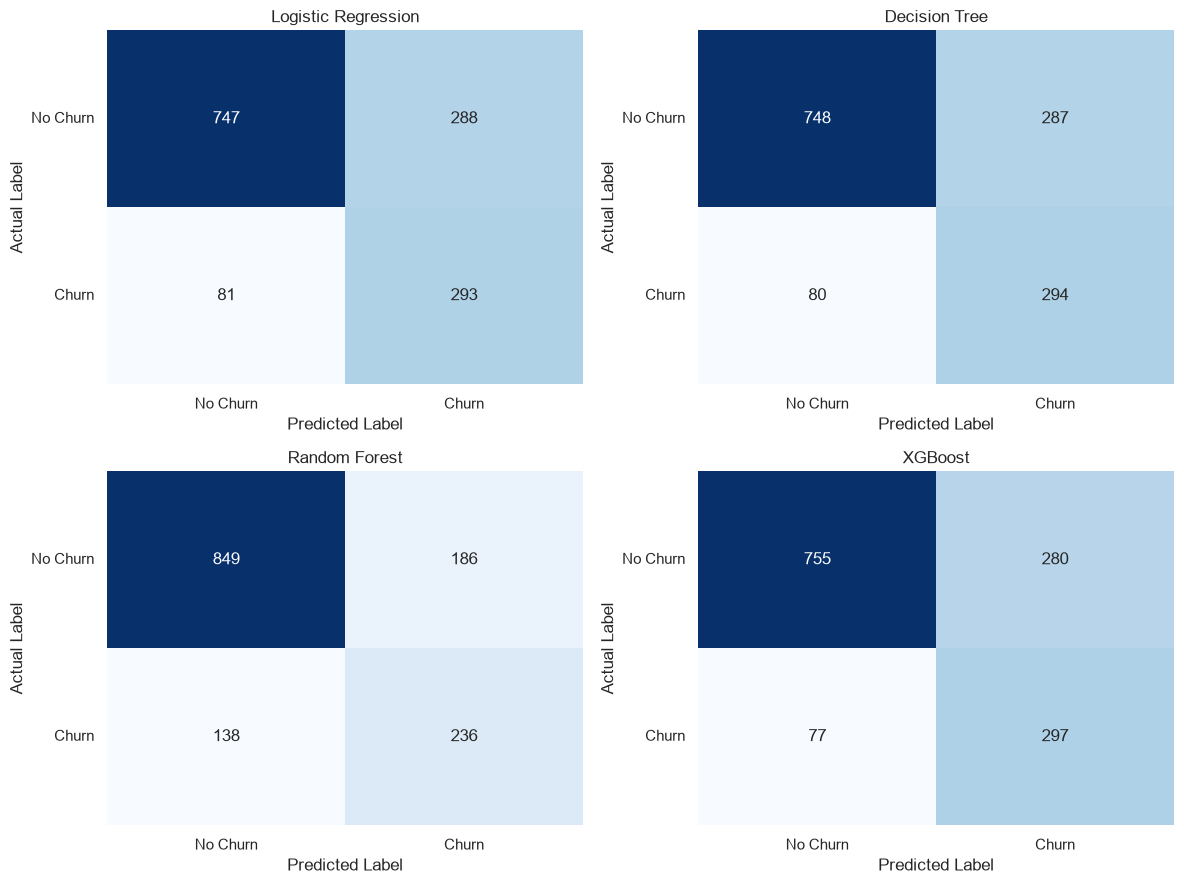

In [23]:
# Display a confusion matrix for each model
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes = axes.flatten()

for ax, (model_name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.set_xticklabels(["No Churn", "Churn"])
    ax.set_yticklabels(["No Churn", "Churn"], rotation=0)

plt.tight_layout()
plt.show()

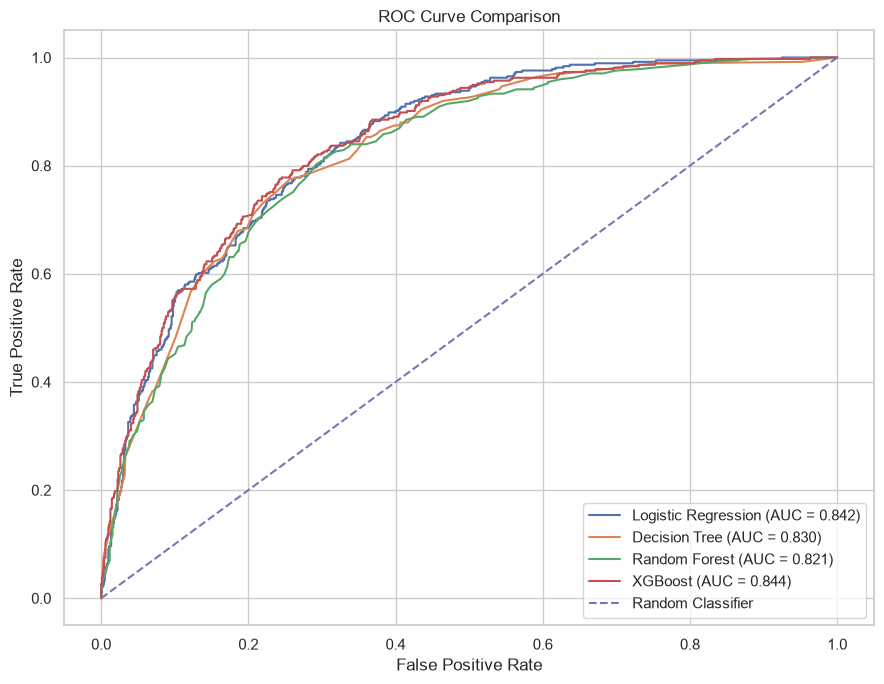

In [24]:
plt.figure(figsize=(9, 7))

for model_name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Select the trained Random Forest pipeline
rf_pipeline = model_pipelines["Random Forest"]

# Calculate permutation importance on the test set
rf_importance = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create an importance table
feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean,
    "Std": rf_importance.importances_std
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Features by Permutation Importance:")
display(feature_importance_df.head(15).round(4))

Top 15 Features by Permutation Importance:


,Feature,Importance,Std
14,Contract,0.0526,0.0060
4,tenure,0.0241,0.0033
7,InternetService,0.0154,0.0054
18,TotalCharges,0.0131,0.0024
8,OnlineSecurity,0.0055,0.0030
15,PaperlessBilling,0.0022,0.0045
11,TechSupport,0.0014,0.0019
9,OnlineBackup,0.0013,0.0031
2,Partner,0.0012,0.0022
16,PaymentMethod,0.0008,0.0042


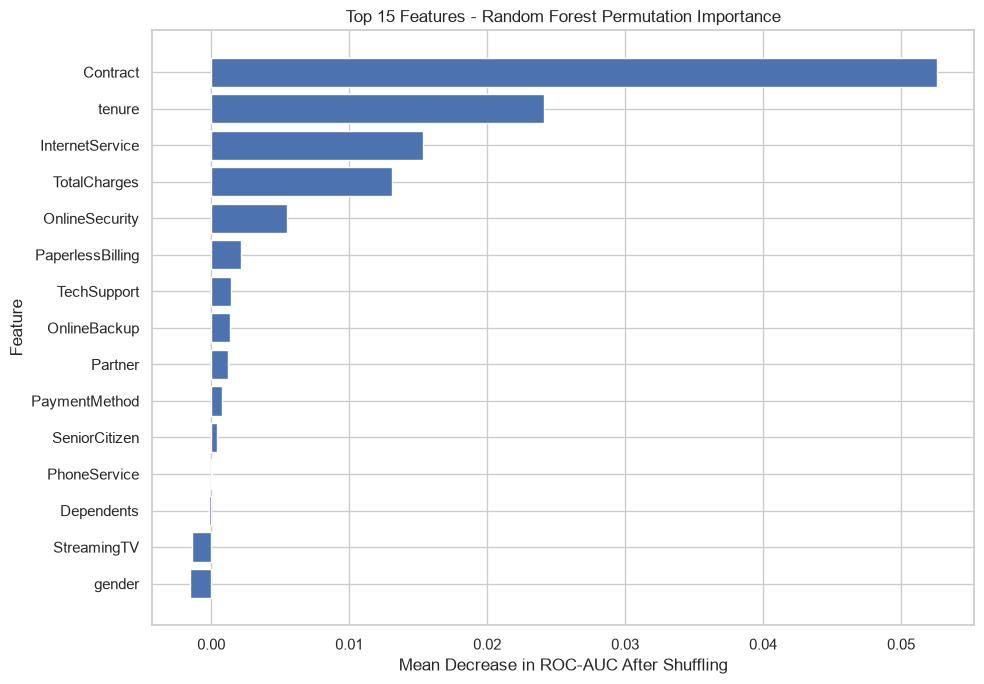

In [26]:
# Select the top 15 features
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features - Random Forest Permutation Importance")
plt.xlabel("Mean Decrease in ROC-AUC After Shuffling")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [27]:
# Identify the highest-scoring model for selected metrics
best_accuracy_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_f1_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

best_recall_model = results_df.loc[
    results_df["Recall"].idxmax()
]

best_auc_model = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

print("Best Model by Accuracy:")
print(best_accuracy_model[["Model", "Accuracy"]].to_string())

print("\nBest Model by F1-Score:")
print(best_f1_model[["Model", "F1-Score"]].to_string())

print("\nBest Model by Recall:")
print(best_recall_model[["Model", "Recall"]].to_string())

print("\nBest Model by ROC-AUC:")
print(best_auc_model[["Model", "ROC-AUC"]].to_string())

Best Model by Accuracy:
Model       Random Forest
Accuracy          0.77005

Best Model by F1-Score:
Model        XGBoost
F1-Score    0.624606

Best Model by Recall:
Model      XGBoost
Recall    0.794118

Best Model by ROC-AUC:
Model       XGBoost
ROC-AUC    0.843655
